# 14 · Écoulement potentiel : l'équation de Laplace

*Notebook 14 du cours. Il suppose le notebook 3 (éléments finis en élasticité 2D) ; les notebooks 6 et 7 (opérateur sans matrice, état adjoint) servent d'outils.*

Pour juger l'aérodynamique d'un bras de drone sous un rotor, il faut un **champ de vitesse** autour de la pièce, à chaque itération de l'optimisation. Le modèle le moins cher qui soit encore un modèle de fluide est l'**écoulement potentiel** : la vitesse dérive d'un potentiel $\varphi$ qui vérifie l'équation de Laplace. Et c'est, au détail près, **le même problème éléments finis que l'élasticité**, avec une inconnue par nœud au lieu de $d$. Tout ce qu'on a construit (grille, connectivité, opérateur sans matrice, solveur direct, état adjoint) se réutilise tel quel.

**Plan.**
1. De la physique à l'équation ;
2. L'élément fini de Laplace (et pourquoi $\mathbf K\mathbf 1=\mathbf 0$) ;
3. Conditions aux limites : pourquoi la sortie doit être imposée ;
4. Écoulement uniforme, conservation du flux, profil de rotor ;
5. Vitesse et pression de Bernoulli ;
6. Validation : le cylindre ;
7. Pénaliser le solide : la conductivité $\kappa(\bar\rho)$ ;
8. Le tampon d'entrée ;
9. Le même code en 3D : la sphère ;
10. Bilan.

**Code promu dans `src`.** `fem/elements.py::laplace_ke0` et `center_gradients` ; `flow/potential.py` (`kappa`, `inlet_load`, `slipstream_inlet_profile`, `PotentialFlow`) ; `flow/aero.py::bernoulli_pressure`. Contrats : C-ELEM-06, C-FLOW-01 à 09.

In [1]:
import sys, math, time
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy import ndimage

RACINE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "aeroptimizer").is_dir())
sys.path.insert(0, str(RACINE / "src"))

from aeroptimizer.errors import ConfigError
from aeroptimizer.fem import elements as el
from aeroptimizer.fem.operators import StructuredFEOperator
from aeroptimizer.flow.aero import bernoulli_pressure
from aeroptimizer.flow.potential import PotentialFlow, inlet_load, kappa, slipstream_inlet_profile
from aeroptimizer.grid import Connectivity, Grid

torch.set_default_dtype(torch.float64)       # convention du projet (CONTRACTS C-CONV-03)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
np.set_printoptions(precision=4, suppress=True, linewidth=120)

def disque(R, nx, nz, sub=8):
    # fraction d'aire d'un disque de rayon R (en cellules) centré dans la boîte : le cylindre « diffus »
    o = (np.arange(sub) + 0.5) / sub
    X = np.arange(nx)[:, None, None, None] + o[None, None, :, None]
    Z = np.arange(nz)[None, :, None, None] + o[None, None, None, :]
    return torch.tensor((((X - nx / 2) ** 2 + (Z - nz / 2) ** 2) <= R * R).mean(axis=(2, 3)))

def cylindre_exact(R, nx, nz):
    # |v|/U de l'écoulement potentiel autour d'un cylindre ISOLÉ (veine infinie), aux centres des cellules
    # (x, z) = position, theta = angle avec l'axe de l'écoulement (z) : |v|^2 = 1 + s^2 - 2 s cos(2 theta), s = (R/r)^2
    X, Z = np.meshgrid(np.arange(nx) + 0.5, np.arange(nz) + 0.5, indexing="ij")
    r = np.hypot(X - nx / 2, Z - nz / 2); th = np.arctan2(np.abs(X - nx / 2), np.abs(Z - nz / 2))
    s = (R / np.maximum(r, R)) ** 2
    return np.sqrt(1 + s**2 - 2 * s * np.cos(2 * th)), r, th

def vitesse(st, nx, nz):
    return st.v.reshape(nx, nz, 2)

def lignes_de_courant(ax, v, h=1.0, masque=None, **kw):
    # masque : booléens (nx, nz), True là où la vitesse n'a pas de sens (dans le corps)
    nx, nz = v.shape[:2]
    x = (np.arange(nx) + 0.5) * h; z = (np.arange(nz) + 0.5) * h
    u, w = v[..., 0].T.numpy(), v[..., 1].T.numpy()
    if masque is not None:
        m = np.asarray(masque).T; u, w = np.ma.masked_where(m, u), np.ma.masked_where(m, w)
    return ax.streamplot(x, z, u, w, **kw)

## 1. De la physique à l'équation

Un fluide **incompressible** vérifie $\nabla\!\cdot\mathbf v=0$ (le flux entrant dans tout volume égale le flux sortant). Un écoulement **irrotationnel** vérifie $\nabla\times\mathbf v=\mathbf 0$ : aucun tourbillon. Un champ sans rotationnel est un gradient, donc $\mathbf v=\nabla\varphi$ pour un champ scalaire $\varphi$, le **potentiel des vitesses**. Les deux conditions ensemble donnent

$$
\nabla\!\cdot(\nabla\varphi)=\Delta\varphi=0 .
$$

C'est l'**équation de Laplace**, l'équation la plus étudiée de la physique : elle décrit aussi la température d'équilibre sans source, le potentiel électrostatique, le gauchissement d'une barre en torsion. La résoudre avec des conditions aux limites adaptées donne le champ de vitesse.

**Pourquoi irrotationnel ?** Dans un fluide sans viscosité qui part d'un état uniforme, le théorème de Kelvin dit que la circulation reste nulle : aucun tourbillon n'apparaît. C'est l'hypothèse qui fait tout le modèle, et elle est fausse près d'une paroi réelle : la viscosité y crée une couche limite, pleine de tourbillons, qui se détache derrière un corps épais. Le notebook 15 mesure ce que cette hypothèse fait perdre ; ici on étudie le modèle pour lui-même.

**Les conditions aux limites.**
- **Paroi solide** (le fluide ne la traverse pas) : $\mathbf v\cdot\mathbf n=\partial_n\varphi=0$. C'est la condition naturelle de la forme faible : on n'a rien à imposer.
- **Entrée** : on connaît la vitesse entrante $U_{\rm in}\ge0$, donc le flux $\partial_n\varphi=-U_{\rm in}$ (la normale sortante est $+\mathbf e_z$ en haut, l'écoulement descend : $v_z=-U$). C'est un chargement, l'analogue d'une force imposée.
- **Sortie** : $\varphi=0$. Le potentiel n'est défini qu'à une constante près ; en fixer la valeur quelque part est obligatoire (§3).

**Le tableau de correspondance avec l'élasticité.**

| | Élasticité (notebooks 3–4) | Potentiel (ce notebook) |
|---|---|---|
| inconnue par nœud | déplacement $\mathbf u$ ($d$ valeurs) | potentiel $\varphi$ (1 valeur) |
| « déformation » | $\boldsymbol\varepsilon=\mathbf B\mathbf u$ | $\mathbf v=\nabla\varphi$ |
| « contrainte » | $\boldsymbol\sigma=\mathbf C\boldsymbol\varepsilon$ | flux $\kappa\nabla\varphi$ |
| matrice élémentaire | $\int\mathbf B^\top\mathbf C\mathbf B$ | $\int(\nabla N)^\top\kappa(\nabla N)$ |
| chargement | forces | flux imposé à l'entrée |
| appui (Dirichlet) | déplacement bloqué | potentiel fixé (sortie) |
| propriété du matériau | $E\,s(\bar\rho)$ (SIMP) | $\kappa(\bar\rho)$, §7 |

C'est pourquoi `StructuredFEOperator` sert aux deux : il prend `ncomp` (1 ou $d$) et la matrice élémentaire `Ke0`, c'est tout.

## 2. L'élément fini de Laplace

On garde l'élément Q1 (carré ou cube, un nœud par coin), les mêmes points de Gauss et les mêmes fonctions de forme $N_a$. La forme faible de $-\nabla\!\cdot(\kappa\nabla\varphi)=0$ donne, pour un élément de conductivité $\kappa_e$,

$$
\mathbf K_e=\kappa_e\,\mathbf K_e^0,\qquad
\mathbf K_e^0=\sum_g w_g\det\mathbf J\;(\nabla N)_g^\top(\nabla N)_g\in\mathbb R^{2^d\times2^d}.
$$

C'est la formule mécanique avec la matrice $\mathbf B$ remplacée par le **gradient** des fonctions de forme. Deux propriétés se voient dans la matrice :

1. $\mathbf K_e^0\mathbf 1=\mathbf 0$ : un potentiel **constant** n'a pas de gradient, donc pas de flux. La matrice est **singulière**, de rang $2^d-1$, comme celle de l'élasticité l'est sur les mouvements de corps rigide ;
2. elle est symétrique semi-définie positive, car $\boldsymbol\varphi^\top\mathbf K_e^0\boldsymbol\varphi=\int|\nabla\varphi|^2\ge0$.

In [2]:
K = el.laplace_ke0(2, (1.0, 1.0))
print("6 * Ke0, carré unité (ordre des coins : bits, poids fort = axe x) :\n", (6 * K).numpy().round(6))
print("\nsomme de chaque ligne :", K.sum(1).numpy())
for d, h in [(2, (1.0, 2.0)), (3, (1.0, 2.0, 0.5))]:
    Kd = el.laplace_ke0(d, h)
    ev = torch.linalg.eigvalsh(Kd)
    print(f"d={d}, h={h} : symétrique {torch.allclose(Kd, Kd.T)} ; valeurs propres (3 plus petites) {ev[:3].numpy()} ; "
          f"rang {torch.linalg.matrix_rank(Kd, atol=1e-12).item()} sur {2**d}")

6 * Ke0, carré unité (ordre des coins : bits, poids fort = axe x) :
 [[ 4. -1. -1. -2.]
 [-1.  4. -2. -1.]
 [-1. -2.  4. -1.]
 [-2. -1. -1.  4.]]

somme de chaque ligne : [-0. -0. -0. -0.]
d=2, h=(1.0, 2.0) : symétrique True ; valeurs propres (3 plus petites) [0.     0.5    0.8333] ; rang 3 sur 4
d=3, h=(1.0, 2.0, 0.5) : symétrique True ; valeurs propres (3 plus petites) [-0.      0.125   0.2083] ; rang 7 sur 8


Les valeurs de la matrice du carré unité sont la matrice classique $\tfrac16\begin{pmatrix}4&-1&-1&-2\\ \cdot&4&-2&-1\\ \cdot&\cdot&4&-1\\ \cdot&\cdot&\cdot&4\end{pmatrix}$ : diagonale $2/3$, voisins sur une arête $-1/6$, coin opposé $-1/3$.

**Le stencil sur une grille.** Si l'on assemble la matrice sur une grille uniforme et qu'on regarde la ligne d'un nœud intérieur, on obtient le stencil de la méthode. Le voici, comparé aux différences finies à 5 points que l'on connaît :

In [3]:
g = Grid((8, 8), (1.0, 1.0))
op = StructuredFEOperator(g, Connectivity(g, 1), el.laplace_ke0(2, g.h), 1, torch.zeros(g.n_nodes, dtype=torch.bool))
w1 = torch.ones(g.n_elems)
delta = torch.zeros(g.n_nodes); centre = 4 * 9 + 4; delta[centre] = 1.0        # nœud (4, 4) de la grille 9×9
col = op.matvec(w1, delta).reshape(9, 9)
print("stencil Q1 (×3) autour d'un nœud intérieur :\n", (3 * col[3:6, 3:6]).numpy().round(6))
print("\ndifférences finies à 5 points (×3) :\n", np.array([[0, -3, 0], [-3, 12, -3], [0, -3, 0]]))
# Le stencil Q1 annule-t-il les champs harmoniques ?  u = 1, x, z, xz, x^2 - z^2  ;  u = x^2 + z^2 n'est pas harmonique.
X, Z = torch.meshgrid(torch.arange(9.0), torch.arange(9.0), indexing="ij")
def residu(u):
    return float(op.matvec(w1, u.reshape(-1)).reshape(9, 9)[1:-1, 1:-1].abs().max())
for nom, u in [("1", X * 0 + 1), ("x", X), ("z", Z), ("x z", X * Z), ("x² − z²", X**2 - Z**2), ("x² + z²  (Δu = 4)", X**2 + Z**2)]:
    print(f"  K u au centre pour u = {nom:<18}: max |K u| = {residu(u):.3e}")

stencil Q1 (×3) autour d'un nœud intérieur :
 [[-1. -1. -1.]
 [-1.  8. -1.]
 [-1. -1. -1.]]

différences finies à 5 points (×3) :
 [[ 0 -3  0]
 [-3 12 -3]
 [ 0 -3  0]]
  K u au centre pour u = 1                 : max |K u| = 2.220e-16
  K u au centre pour u = x                 : max |K u| = 1.776e-15
  K u au centre pour u = z                 : max |K u| = 2.665e-15
  K u au centre pour u = x z               : max |K u| = 1.421e-14
  K u au centre pour u = x² − z²           : max |K u| = 1.243e-14
  K u au centre pour u = x² + z²  (Δu = 4) : max |K u| = 4.000e+00


Le stencil Q1 sur un carré est $\tfrac13\begin{pmatrix}-1&-1&-1\\-1&8&-1\\-1&-1&-1\end{pmatrix}$ : il utilise les 8 voisins (le coin vaut autant que l'arête), alors que les différences finies à 5 points n'en utilisent que 4. Les deux sont consistants avec $-\Delta$.

La vérification est exacte : le stencil annule $1,\;x,\;z,\;xz$ et $x^2-z^2$, qui sont les polynômes harmoniques du degré $\le2$ ; il donne une valeur de module $4$ pour $x^2+z^2$ (de laplacien $4$ : l'opérateur intègre $-\Delta u$ contre la fonction de forme, d'intégrale $h^2=1$). Un élément Q1 reproduit donc exactement les champs harmoniques simples : c'est le **test des pièces** de l'élasticité, version Laplace.

## 3. Conditions aux limites : pourquoi fixer la sortie

Sans aucun potentiel imposé, la matrice $\mathbf K$ assemblée a pour noyau les constantes ($\mathbf K\mathbf 1=\mathbf 0$), donc **le système n'a pas de solution unique** ; et il n'en a même pas du tout si le second membre n'est pas orthogonal au noyau. Ici le second membre est le flux d'entrée $\mathbf b$, et son produit avec $\mathbf 1$ est le **flux total entrant**. Un fluide incompressible ne peut pas entrer dans une boîte fermée : il faut une sortie.

In [4]:
g = Grid((5, 6), (1.0, 1.0))
pf = PotentialFlow(g, torch.full((5,), 1.0), n_pad=0)
w1 = torch.ones(g.n_elems)
K0 = pf.op_neumann.assemble_csr(w1).toarray()                    # SANS condition de Dirichlet
ev = np.linalg.eigvalsh(K0)
print("pur Neumann : plus petites valeurs propres :", ev[:3], f" rang {np.linalg.matrix_rank(K0, tol=1e-10)} sur {g.n_nodes}")
b = pf.b.numpy()
print(f"flux total entrant  b·1 = {b.sum():+.3f}  ->  composante du second membre sur le noyau, impossible à équilibrer")
sol, res, rk, sv = np.linalg.lstsq(K0, b, rcond=None)
print(f"meilleure solution au sens des moindres carrés : résidu ‖K φ − b‖ = {np.linalg.norm(K0 @ sol - b):.3f}  (= |b·1|/√N = {abs(b.sum())/math.sqrt(g.n_nodes):.3f}, jamais nul)")
K = pf.op.assemble_csr(w1).toarray()                              # AVEC la sortie fixée (z = 0)
ev = np.linalg.eigvalsh(K)
print(f"\navec la sortie fixée : symétrique {np.allclose(K, K.T)}, plus petite valeur propre {ev[0]:.4f} > 0 : défini positif")
print("le solveur direct et l'état adjoint du notebook 7 s'appliquent donc sans changement.")

pur Neumann : plus petites valeurs propres : [-0.      0.1619  0.2224]  rang 41 sur 42
flux total entrant  b·1 = -5.000  ->  composante du second membre sur le noyau, impossible à équilibrer
meilleure solution au sens des moindres carrés : résidu ‖K φ − b‖ = 0.772  (= |b·1|/√N = 0.772, jamais nul)

avec la sortie fixée : symétrique True, plus petite valeur propre 0.0482 > 0 : défini positif
le solveur direct et l'état adjoint du notebook 7 s'appliquent donc sans changement.


Le résidu des moindres carrés vaut exactement $|\mathbf b\cdot\mathbf1|/\sqrt N$ : tout le défaut est dans la direction du noyau et rien ne peut le corriger. Fixer $\varphi=0$ sur la sortie lève les deux problèmes à la fois (unicité et existence) : le flux qui entre trouve où sortir, et le système devient défini positif.

**Ce que fait `PotentialFlow`.** Le flux d'entrée est chargé sur la face du haut ($z=z_{\max}$), le potentiel est fixé sur la face du bas, les parois latérales ne reçoivent rien (glissement, condition naturelle).

## 4. Écoulement uniforme, conservation du flux, profil de rotor

**Premier test : sans obstacle** ($\bar\rho\equiv0$), la solution exacte est $\mathbf v=-U\mathbf e_z$ partout et $\varphi=-Uz$. Elle est dans l'espace Q1 (un champ linéaire), donc la solution éléments finis doit la retrouver à la précision machine, sur n'importe quelle grille, même avec des éléments de formes différentes sur chaque axe.

In [5]:
for shape, h in [((10, 14), (0.5, 2.0)), ((4, 5, 7), (0.5, 1.0, 2.0))]:
    g = Grid(shape, h); U = 2.5
    pf = PotentialFlow(g, torch.full(shape[:-1], U), n_pad=0)
    st = pf.solve(torch.zeros(shape))
    voulu = torch.zeros(g.n_elems, g.d); voulu[:, -1] = -U
    z = (torch.arange(g.n_nodes) % (shape[-1] + 1)) * h[-1]
    fin, fout = pf.fluxes(torch.zeros(shape))
    print(f"d={g.d}, h={h} : max |v + U e_z| = {float((st.v - voulu).abs().max()):.1e} ; max |φ + U z| = {float((st.phi + U*z).abs().max()):.1e} ; "
          f"flux entrant {fin:.6f}, sortant {fout:.6f}, attendu {U*math.prod(h[:-1])*math.prod(s for s in shape[:-1]):.6f}")

d=2, h=(0.5, 2.0) : max |v + U e_z| = 5.2e-13 ; max |φ + U z| = 1.0e-11 ; flux entrant 12.500000, sortant 12.500000, attendu 12.500000
d=3, h=(0.5, 1.0, 2.0) : max |v + U e_z| = 7.8e-14 ; max |φ + U z| = 7.0e-13 ; flux entrant 25.000000, sortant 25.000000, attendu 25.000000


**Conservation du flux.** La somme des réactions sur les nœuds de sortie (le flux qui quitte le domaine) doit égaler le flux entrant, avec ou sans obstacle : c'est la contrainte $\nabla\!\cdot\mathbf v=0$ intégrée. C'est une vérification gratuite et très sensible : une condition aux limites mal posée ou un tampon d'entrée trop mince la casse.

**Un profil d'entrée de rotor.** Sous un rotor, le fluide n'entre que sur l'empreinte du disque, à la vitesse induite $U_h=\sqrt{T/(2\rho_aA)}$ (théorie de la quantité de mouvement), multipliée par un facteur de contraction du sillage $k_w\in[1,2]$. `slipstream_inlet_profile` construit ce profil ; ici avec une poussée de $10\,$N sur un disque de $0{,}02\,\mathrm{m}^2$.

U_h = 14.286 m/s ; vitesse d'entrée sur l'empreinte 21.429 m/s, ailleurs 0.0
flux entrant / sortant : (428.57142857142856, 428.57142857133215)


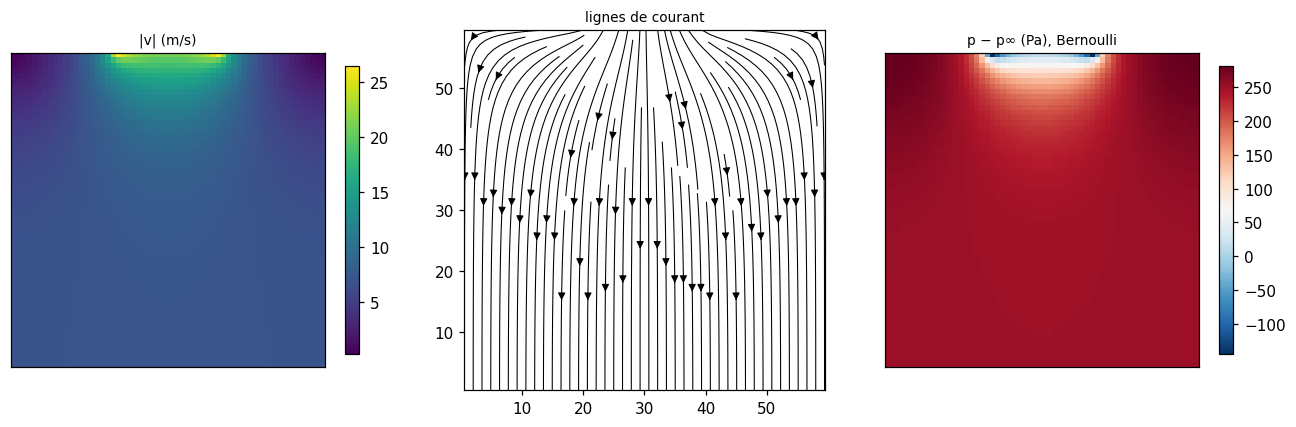

In [6]:
nx = nz = 60
g = Grid((nx, nz), (1.0, 1.0))
masque = torch.zeros(nx, dtype=torch.bool); masque[20:40] = True              # empreinte du rotor : le tiers central
prof = slipstream_inlet_profile(g, masque, thrust_N=10.0, rotor_area_m2=0.02, rho_air=1.225, k_w=1.5, U_inf=0.0)
print(f"U_h = {math.sqrt(10/(2*1.225*0.02)):.3f} m/s ; vitesse d'entrée sur l'empreinte {float(prof.max()):.3f} m/s, ailleurs {float(prof.min()):.1f}")
pf = PotentialFlow(g, prof, n_pad=0)
st = pf.solve(torch.zeros(nx, nz))
print("flux entrant / sortant :", pf.fluxes(torch.zeros(nx, nz)))
v = vitesse(st, nx, nz); vit = v.pow(2).sum(-1).sqrt()
fig, axs = plt.subplots(1, 3, figsize=(12, 3.8))
im = axs[0].imshow(vit.numpy().T, origin="lower", cmap="viridis"); plt.colorbar(im, ax=axs[0], shrink=0.8); axs[0].set_title("|v| (m/s)", fontsize=9)
lignes_de_courant(axs[1], v, density=1.4, color="k", linewidth=0.7); axs[1].set_title("lignes de courant", fontsize=9); axs[1].set_aspect("equal")
im = axs[2].imshow(st.p_rel.reshape(nx, nz).numpy().T, origin="lower", cmap="RdBu_r"); plt.colorbar(im, ax=axs[2], shrink=0.8); axs[2].set_title("p − p∞ (Pa), Bernoulli", fontsize=9)
for a in (axs[0], axs[2]): a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

Le jet entre par le tiers central ; comme la sortie est un potentiel constant sur toute la face du bas, il s'étale vers les côtés en descendant. Ce n'est pas la physique d'un vrai sillage de rotor (qui se contracte), c'est la conséquence des conditions aux limites choisies : **l'écoulement est piloté par ses conditions aux limites**, et il faut les choisir en connaissant ce qu'elles font. Dans le projet, le tampon d'entrée du §8 éloigne l'obstacle de ce profil non uniforme.

## 5. Vitesse et pression de Bernoulli

**La vitesse.** Pour un élément Q1, $\mathbf v=\nabla\varphi$ n'est pas continue d'un élément à l'autre (le potentiel l'est, son gradient non). On la prend au **centre de l'élément**, où le gradient d'un champ Q1 est le plus précis (c'est le point de superconvergence sur grille uniforme, vérifié au §6) :

$$
\mathbf v_e=\sum_a\varphi_a\,\nabla N_a(\mathbf 0).
$$

`center_gradients` donne ces $\nabla N_a(\mathbf0)$ ; ils valent la moyenne des gradients aux points de Gauss, car le gradient Q1 est affine.

**La pression.** Pour un écoulement stationnaire irrotationnel d'un fluide incompressible, l'équation de Bernoulli donne $p+\tfrac12\rho_a|\mathbf v|^2=$ constante dans tout l'écoulement. Avec $p_\infty$ et $U_{\rm ref}$ la pression et la vitesse de référence :

$$
p-p_\infty=\tfrac12\rho_a\big(U_{\rm ref}^2-|\mathbf v|^2\big)=\tfrac12\rho_aU_{\rm ref}^2\,C_p,\qquad C_p=1-\frac{|\mathbf v|^2}{U_{\rm ref}^2}.
$$

Le coefficient de pression $C_p$ vaut $1$ aux **points d'arrêt** (là où le fluide s'immobilise) et devient négatif là où il accélère. La pression est **entièrement déterminée par la vitesse** : aucune équation de plus à résoudre, et c'est tout ce que ce modèle sait dire de la force du fluide (notebook 15).

## 6. Validation : le cylindre

Le cylindre de rayon $R$ dans un écoulement uniforme $U$ a une solution analytique en veine infinie : $\varphi=U(r+R^2/r)\cos\theta$, soit

$$
v_r=U\Big(1-\frac{R^2}{r^2}\Big)\cos\theta,\qquad v_\theta=-U\Big(1+\frac{R^2}{r^2}\Big)\sin\theta,\qquad
\frac{|\mathbf v|^2}{U^2}=1+s^2-2s\cos2\theta,\ \ s=\frac{R^2}{r^2},
$$

où $\theta$ est l'angle avec l'axe de l'écoulement. Sur la paroi ($r=R$) : $|\mathbf v|=2U|\sin\theta|$, d'où $C_p(\theta)=1-4\sin^2\theta$ (le cylindre accélère le fluide à $2U$ sur ses épaules).

**Comment mettre un cylindre dans une grille ?** Pas de maillage qui épouse la forme : on garde la grille régulière et on donne à chaque cellule sa **fraction d'aire** de disque ($\bar\rho\in[0,1]$), puis la conductivité $\kappa(\bar\rho)$ du §7 rend le solide quasi imperméable. C'est exactement ce que fait l'optimisation, qui ne produit jamais de contour net.

**Deux sources d'écart avec la formule.** (i) La veine est **bornée par des parois glissantes** : elle accélère l'écoulement (le blocage $2R/W$), un effet physique du montage, pas une erreur numérique. (ii) L'interface diffuse. On les sépare en regardant l'erreur sur un anneau à distance du corps ($1{,}5R<r<3R$, où l'interface ne compte plus).

résolution 256×320 : 0.27 s ; flux entrant/sortant (256.0, 255.99999999754715)
anneau r = 1.1 R : écart maximal numérique − formule sur C_p : 0.620
anneau r = 1.3 R : écart maximal numérique − formule sur C_p : 0.139


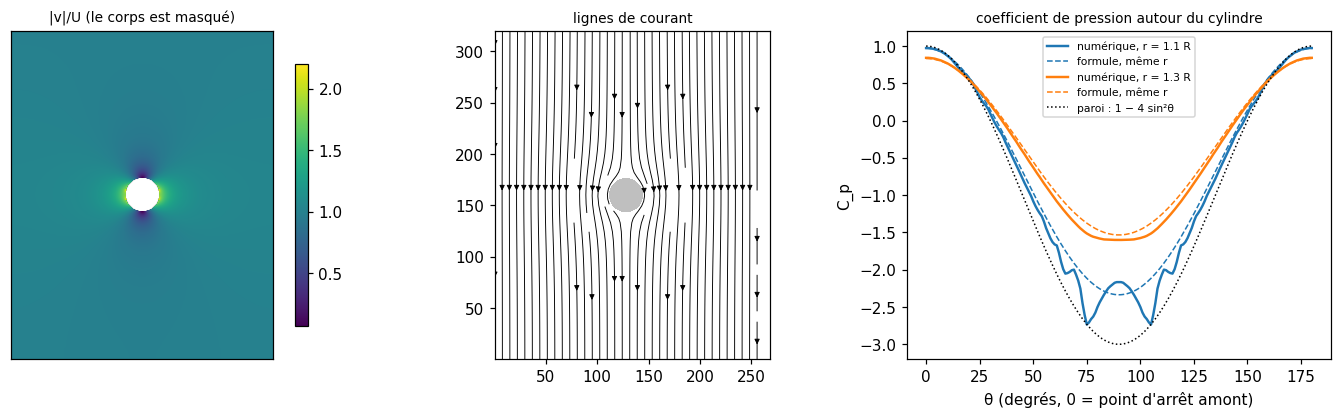

erreur moyenne de |v|/U sur l'anneau 1,5R–3R : 0.0144  (blocage 2R/W = 0.125)


In [7]:
R, nx, nz = 16, 256, 320
g = Grid((nx, nz), (1.0, 1.0)); rho = disque(R, nx, nz)
pf = PotentialFlow(g, torch.full((nx,), 1.0), n_pad=4)
t = time.time(); st = pf.solve(rho); print(f"résolution {nx}×{nz} : {time.time()-t:.2f} s ; flux entrant/sortant {pf.fluxes(rho)}")
v = vitesse(st, nx, nz); vit = v.pow(2).sum(-1).sqrt().numpy()
exact, r, th = cylindre_exact(R, nx, nz)
cp = 1 - vit**2

fig, axs = plt.subplots(1, 3, figsize=(13, 3.9))
im = axs[0].imshow(np.where(rho.numpy() > 0.5, np.nan, vit).T, origin="lower", cmap="viridis", vmax=2.2); plt.colorbar(im, ax=axs[0], shrink=0.8)
axs[0].set_title("|v|/U (le corps est masqué)", fontsize=9); axs[0].set_xticks([]); axs[0].set_yticks([])
lignes_de_courant(axs[1], v, masque=(rho.numpy() > 0.5), density=1.2, color="k", linewidth=0.6, arrowsize=0.7)
axs[1].contourf(np.arange(nx) + .5, np.arange(nz) + .5, rho.numpy().T, levels=[0.5, 1.1], colors=["0.75"]); axs[1].set_aspect("equal"); axs[1].set_title("lignes de courant", fontsize=9)
# C_p sur des anneaux autour du corps : interpolation bilinéaire du C_p numérique, comparé à la formule au même rayon
ang = np.linspace(0, np.pi, 181)
for k, (rr, c) in enumerate([(1.1 * R, "C0"), (1.3 * R, "C1")]):
    xs = nx / 2 + rr * np.sin(ang); zs = nz / 2 + rr * np.cos(ang)
    num = ndimage.map_coordinates(cp, [xs - 0.5, zs - 0.5], order=1)
    s = (R / rr) ** 2; ana = 1 - (1 + s**2 - 2 * s * np.cos(2 * ang))
    print(f"anneau r = {rr/R:.1f} R : écart maximal numérique − formule sur C_p : {np.abs(num - (1 - (1 + ((R/rr)**2)**2 - 2 * (R/rr)**2 * np.cos(2 * ang)))).max():.3f}")
    axs[2].plot(np.degrees(ang), num, c, lw=1.6, label=f"numérique, r = {rr/R:.1f} R"); axs[2].plot(np.degrees(ang), ana, c + "--", lw=1, label="formule, même r")
axs[2].plot(np.degrees(ang), 1 - 4 * np.sin(ang) ** 2, "k:", lw=1, label="paroi : 1 − 4 sin²θ")
axs[2].set_xlabel("θ (degrés, 0 = point d'arrêt amont)"); axs[2].set_ylabel("C_p"); axs[2].legend(fontsize=7); axs[2].set_title("coefficient de pression autour du cylindre", fontsize=9)
plt.tight_layout(); plt.show()
sel = (r > 1.5 * R) & (r < 3 * R)
print(f"erreur moyenne de |v|/U sur l'anneau 1,5R–3R : {np.abs(vit - exact)[sel].mean():.4f}  (blocage 2R/W = {2*R/nx:.3f})")

**Lecture de la figure.** Le point d'arrêt ($C_p\to1$ à $\theta=0$) et l'accélération sur les épaules sont bien là. À $r=1{,}3R$ (environ $5$ cellules de la paroi), la courbe numérique suit la formule au même rayon à $0{,}14$ près au pire. **Tout près de la paroi** ($r=1{,}1R$, moins de $2$ cellules), l'écart monte à $0{,}62$ : la courbe est en dents de scie et son creux ($-2{,}75$) dépasse celui de la formule ($-2{,}3$). La couche d'interface, faite de cellules en escalier, rend la pression numérique **peu fiable à moins de deux cellules du corps** ; c'est important pour le notebook 15, qui calcule la force à cet endroit.

Reste l'écart de quelques pour cent sur l'anneau lointain. Est-ce le maillage ou la veine ? On le sépare en faisant varier **la largeur de la veine à rayon fixe**, puis **la finesse du maillage à veine fixe**.

In [8]:
def erreur_anneau(R, W, L, q=3.0, kappa_min=1e-6):
    g = Grid((W, L), (1.0, 1.0)); rho = disque(R, W, L)
    st = PotentialFlow(g, torch.full((W,), 1.0), n_pad=4, q=q, kappa_min=kappa_min).solve(rho)
    vit = vitesse(st, W, L).pow(2).sum(-1).sqrt().numpy(); ex, r, _ = cylindre_exact(R, W, L)
    sel = (r > 1.5 * R) & (r < 3 * R)
    return np.abs(vit - ex)[sel].mean()

print("(a) largeur de veine W variable, R = 8, longueur 20 R :")
print(f"{'W/2R':>6} {'erreur':>9}")
for W in (24, 32, 48, 64, 96, 128, 192):
    print(f"{W/16:>6.2f} {erreur_anneau(8, W, 160):>9.4f}")
print("\n(b) longueur de veine L variable, R = 8, W = 128 (les conditions d'entrée et de sortie sont-elles assez loin ?) :")
for L in (48, 80, 120, 160, 240):
    print(f"  L/2R = {L/16:>5.1f} : {erreur_anneau(8, 128, L):.4f}")
print("\n(c) raffinement à veine FIXE (W = 16 R, L = 20 R) :")
print(f"{'R (cellules)':>13} {'erreur':>9}")
for R_ in (4, 8, 16, 32):
    print(f"{R_:>13d} {erreur_anneau(R_, 16*R_, 20*R_):>9.4f}")

(a) largeur de veine W variable, R = 8, longueur 20 R :
  W/2R    erreur
  1.50    0.2053
  2.00    0.1901
  3.00    0.1073
  4.00    0.0589
  6.00    0.0266
  8.00    0.0163


 12.00    0.0103

(b) longueur de veine L variable, R = 8, W = 128 (les conditions d'entrée et de sortie sont-elles assez loin ?) :
  L/2R =   3.0 : 0.0370
  L/2R =   5.0 : 0.0174
  L/2R =   7.5 : 0.0163
  L/2R =  10.0 : 0.0163


  L/2R =  15.0 : 0.0163

(c) raffinement à veine FIXE (W = 16 R, L = 20 R) :
 R (cellules)    erreur
            4    0.0204
            8    0.0163


           16    0.0144


           32    0.0137


**Lecture.**
- **(a)** L'erreur chute de $0{,}21$ à $0{,}010$ quand la veine passe de $1{,}5$ à $12$ diamètres : c'est le **blocage** des parois (une demi-veine étroite accélère le fluide qui contourne). L'écart de quelques pour cent du cas à $W/2R=8$ est de cette origine, pas numérique.
- **(b)** À $3$ diamètres de longueur, l'erreur double ($0{,}037$ : l'entrée et la sortie sont trop proches du corps) ; à $5$ diamètres elle est à $7\,\%$ de son plateau ($0{,}0174$) ; à partir de $7{,}5$ diamètres plus rien ne change ($0{,}0163$). La veine du projet doit respecter cet ordre de grandeur de part et d'autre du corps.
- **(c)** À veine fixe, l'erreur ne diminue presque plus avec le raffinement (de $0{,}020$ à $0{,}014$ pour $R=4\to32$) : elle est dominée par le blocage (rapport $2R/W=0{,}125$ pour $W=16R$), pas par le maillage.

**La vraie convergence en maillage** ne se voit donc pas sur le cylindre en veine bornée. On l'isole avec un cas à **solution exacte lisse**, dans la même boîte à parois glissantes : un potentiel $\varphi=-U_0z+a\cos(kx)\sinh(kz)/k$ avec $k=\pi/W$ (qui annule $\partial_x\varphi$ aux parois), obtenu en imposant à l'entrée la vitesse $U_{\rm in}(x)=U_0-a\cosh(kL)\cos(kx)$. L'erreur sur la vitesse aux centres d'éléments doit décroître comme $h^2$ (contrat C-FLOW-08, qui demande au moins un ordre 1).

In [9]:
def cas_lisse(n, Lz=1.25):
    k = math.pi; a = 0.5 / math.cosh(k * Lz); nx, nz, h = n, int(Lz * n), 1.0 / n
    xs = torch.arange(nx + 1) * h
    ue = 1.0 - a * math.cosh(k * Lz) * (torch.sin(k * xs[1:]) - torch.sin(k * xs[:-1])) / (k * h)     # moyenne par élément de U_in(x)
    st = PotentialFlow(Grid((nx, nz), (h, h)), ue, n_pad=0, u_ref=1.0).solve(torch.zeros(nx, nz))
    X, Z = torch.meshgrid((torch.arange(nx) + 0.5) * h, (torch.arange(nz) + 0.5) * h, indexing="ij")
    vx, vz = -a * torch.sin(k * X) * torch.sinh(k * Z), -1 + a * torch.cos(k * X) * torch.cosh(k * Z)
    v = st.v.reshape(nx, nz, 2)
    return float(torch.sqrt((v[..., 0] - vx) ** 2 + (v[..., 1] - vz) ** 2).max())

print(f"{'n':>5} {'max |v - v_exact|':>18} {'ordre':>7}")
prev = None
for n in (8, 16, 32, 64, 128):
    e = cas_lisse(n); print(f"{n:>5d} {e:>18.3e} {'' if prev is None else f'{math.log2(prev/e):>7.2f}'}"); prev = e

    n  max |v - v_exact|   ordre
    8          6.163e-03 
   16          1.589e-03    1.96
   32          4.006e-04    1.99
   64          1.003e-04    2.00
  128          2.510e-05    2.00


L'ordre vaut $2$ ($1{,}96$ à $2{,}00$) : le solveur est correct, et la raison de l'erreur du cylindre est bien la géométrie et le blocage, pas un défaut de la discrétisation.

**Et le cylindre diffus, seul ?** On suit la vitesse en un point fixe de l'espace ($2R$ de l'axe, à mi-hauteur) quand on raffine le maillage à **taille physique fixe** (domaine $16\times20$, $R=1$), comparée à la solution la plus fine ($n=64$ cellules par rayon).

In [10]:
valeurs = {}
for n in (4, 8, 16, 32, 64):
    nx_, nz_ = 16 * n, 20 * n; g_ = Grid((nx_, nz_), (1.0 / n, 1.0 / n))
    rho_ = disque(n, nx_, nz_, sub=8 if n < 64 else 4)
    s_ = PotentialFlow(g_, torch.full((nx_,), 1.0), n_pad=4).solve(rho_)
    sp_ = vitesse(s_, nx_, nz_).pow(2).sum(-1).sqrt()
    i, j = nx_ // 2 + 2 * n, nz_ // 2                       # nœud à 2R de l'axe : moyenne des 4 éléments voisins
    valeurs[n] = float(sp_[i - 1:i + 1, j - 1:j + 1].mean())
ref = valeurs[64]
print(f"{'cellules par rayon':>19} {'|v|/U au point':>15} {'écart à n=64':>13} {'ordre':>7}   (analytique, veine infinie : 1,2500)")
prev = None
for n in (4, 8, 16, 32):
    e = abs(valeurs[n] - ref); print(f"{n:>19d} {valeurs[n]:>15.5f} {e:>13.5f} {'' if prev is None else f'{math.log2(prev/e):>7.2f}'}"); prev = e

 cellules par rayon  |v|/U au point  écart à n=64   ordre   (analytique, veine infinie : 1,2500)
                  4         1.28478       0.01612 
                  8         1.27854       0.00988    0.71
                 16         1.27345       0.00478    1.05
                 32         1.27042       0.00176    1.44


L'ordre observé sur le cylindre diffus est de **$0{,}7$ à $1{,}4$** selon l'intervalle, et surtout irrégulier : on ne gagne pas le $h^2$ du cas lisse. C'est le prix de la représentation en fractions d'aire : la forme du disque est approchée de façon grossière (escalier adouci), et l'erreur de forme se mélange à l'erreur de discrétisation. Le contrat C-FLOW-08 demande un ordre $\ge1$ ; on le vérifie sur le cas lisse. **Sur un design réel (interface diffuse, formes quelconques), n'attendez pas mieux qu'un ordre $\approx1$ et un résultat irrégulier d'une résolution à l'autre.**

## 7. Pénaliser le solide : la conductivité $\kappa(\bar\rho)$

On résout **un seul problème sur tout le domaine**, avec une conductivité qui dépend de la densité :

$$
-\nabla\!\cdot\big(\kappa(\bar\rho)\nabla\varphi\big)=0,\qquad
\kappa(\bar\rho)=\kappa_{\min}+(1-\kappa_{\min})(1-\bar\rho)^q,\quad \kappa_{\min}=10^{-6},\ q=3 .
$$

Fluide ($\bar\rho=0$) : $\kappa=1$, Laplace normal. Solide ($\bar\rho=1$) : $\kappa=\kappa_{\min}\approx0$, **aucun flux ne passe**, ce qui reproduit la condition de paroi $\partial_n\varphi=0$. C'est l'analogue, pour Laplace, de ce que SIMP fait à la rigidité. Deux paramètres à régler : $\kappa_{\min}$ et $q$ (les valeurs 1e-6 et 3 sont des choix du projet, à valider).

(a) κ_min  (R = 8, W = 128, q = 3) :
   κ_min  fuite de flux  erreur anneau
   1e-01       2.33e-02         0.0175
   1e-02       2.71e-03         0.0147
   1e-03       2.93e-04         0.0161


   1e-04       3.07e-05         0.0163
   1e-06       3.10e-07         0.0163
   1e-08       3.10e-09         0.0163

(b) exposant q  (κ_min = 1e-6) : erreur moyenne sur l'anneau 1,5R–3R, et sur la couche de 1,5 cellule contre le corps
  q    anneau   couche contre le corps
  1    0.0132                   0.0185


  2    0.0149                   0.0420
  3    0.0163                   0.0559
  5    0.0179                   0.0685


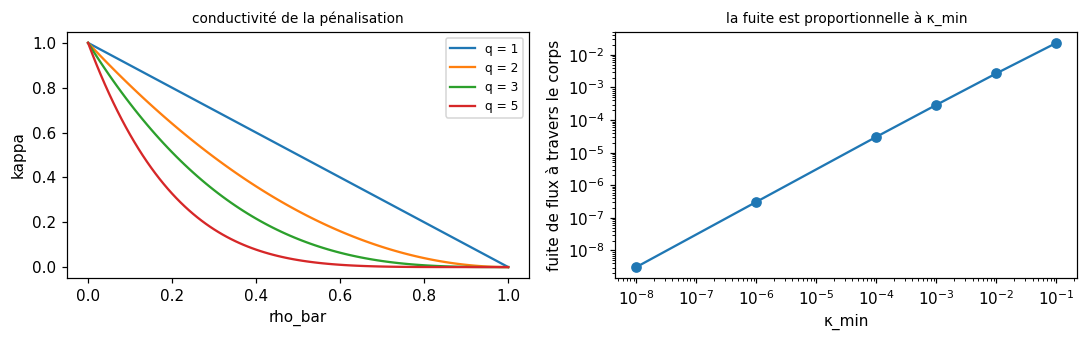

In [11]:
rr = np.linspace(0, 1, 101)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for q in (1, 2, 3, 5): ax[0].plot(rr, kappa(torch.tensor(rr), 1e-6, q).numpy(), label=f"q = {q}")
ax[0].set_xlabel("rho_bar"); ax[0].set_ylabel("kappa"); ax[0].legend(fontsize=8); ax[0].set_title("conductivité de la pénalisation", fontsize=9)

def fuite(R, W, L, kappa_min, q=3.0):
    # part du flux de la rangée centrale qui traverse le corps (devrait être 0 pour un solide imperméable)
    g = Grid((W, L), (1.0, 1.0)); rho = disque(R, W, L); pf = PotentialFlow(g, torch.full((W,), 1.0), n_pad=4, kappa_min=kappa_min, q=q)
    st = pf.solve(rho)
    k = pf.conductivity(rho).reshape(W, L).numpy(); vz = -vitesse(st, W, L)[..., 1].numpy()
    ligne = k[:, L // 2] * vz[:, L // 2]; dedans = np.abs(np.arange(W) + 0.5 - W / 2) < R
    sp = vitesse(st, W, L).pow(2).sum(-1).sqrt().numpy(); ex, r, _ = cylindre_exact(R, W, L); sel = (r > 1.5 * R) & (r < 3 * R)
    return ligne[dedans].sum() / ligne.sum(), np.abs(sp - ex)[sel].mean()

print("(a) κ_min  (R = 8, W = 128, q = 3) :")
print(f"{'κ_min':>8} {'fuite de flux':>14} {'erreur anneau':>14}")
for km in (1e-1, 1e-2, 1e-3, 1e-4, 1e-6, 1e-8):
    f, e = fuite(8, 128, 160, km); print(f"{km:>8.0e} {f:>14.2e} {e:>14.4f}")
print("\n(b) exposant q  (κ_min = 1e-6) : erreur moyenne sur l'anneau 1,5R–3R, et sur la couche de 1,5 cellule contre le corps")
print(f"{'q':>3} {'anneau':>9} {'couche contre le corps':>24}")
for q in (1, 2, 3, 5):
    g = Grid((128, 160), (1.0, 1.0)); rho = disque(8, 128, 160)
    sp = vitesse(PotentialFlow(g, torch.full((128,), 1.0), n_pad=4, q=q).solve(rho), 128, 160).pow(2).sum(-1).sqrt().numpy()
    ex, r, _ = cylindre_exact(8, 128, 160); an = (r > 12) & (r < 24); couche = (r > 8.5) & (r < 10)
    print(f"{q:>3d} {np.abs(sp - ex)[an].mean():>9.4f} {np.abs(sp - ex)[couche].mean():>24.4f}")
ax[1].semilogy(*zip(*[(km, fuite(8, 128, 160, km)[0]) for km in (1e-1, 1e-2, 1e-3, 1e-4, 1e-6, 1e-8)]), "o-"); ax[1].set_xscale("log")
ax[1].set_xlabel("κ_min"); ax[1].set_ylabel("fuite de flux à travers le corps"); ax[1].set_title("la fuite est proportionnelle à κ_min", fontsize=9)
plt.tight_layout(); plt.show()

**Lecture.**
- **(a)** La fuite de flux à travers le corps est **proportionnelle à $\kappa_{\min}$** ($2{,}3\times10^{-2}$ pour $\kappa_{\min}=10^{-1}$, $3\times10^{-7}$ pour $10^{-6}$), tandis que l'erreur à distance du corps **ne bouge presque pas** dès que $\kappa_{\min}\le10^{-2}$. Un $\kappa_{\min}$ de $10^{-2}$ suffirait donc pour la précision en champ lointain, avec un système mieux conditionné ; $10^{-6}$ garantit un solide étanche à $10^{-6}$ près. Le choix est une affaire de **conditionnement contre étanchéité**. Avec le solveur direct (erreur inverse $\le10^{-10}$, notebook 6), $10^{-6}$ passe sans difficulté.
- **(b)** À distance, $q$ compte peu ($0{,}013$ à $0{,}018$). **Contre le corps**, l'erreur grandit nettement avec $q$ : $0{,}018$ pour $q=1$, $0{,}056$ pour $q=3$, $0{,}068$ pour $q=5$. Une cellule d'interface à moitié pleine ($\bar\rho=0{,}5$) a une conductivité $0{,}5$ pour $q=1$ mais $0{,}125$ pour $q=3$ : l'interface est plus étanche que ce que son contenu physique justifie. Le projet fixe $q=3$ ⚠ ; ce test, fait avec des fractions d'aire exactes, plaide plutôt pour un $q$ plus petit, mais $\bar\rho$ dans une optimisation est lissé par le filtre et la projection, et pas une fraction d'aire : **à vérifier sur des designs réels avant de modifier le choix**.

Cette erreur de **couche contre le corps** n'est pas anodine : c'est là que le notebook 15 prélève la pression pour calculer la force. On y reviendra.

## 8. Le tampon d'entrée

Que se passe-t-il si le solide touche la face d'entrée ? Le flux $U_{\rm in}$ imposé doit alors traverser un milieu de conductivité $\kappa_{\min}$, ce qui exige un gradient $\sim U/\kappa_{\min}$ : une vitesse énorme et un potentiel géant. On place un bloc de 16 cellules de large, d'épaisseur 6, à une distance variable de l'entrée.

In [12]:
nx, nz = 64, 96; g = Grid((nx, nz), (1.0, 1.0))
print(f"{'fluide entre le bloc et l entrée':>34} {'max |v|':>12} {'max |φ|':>12} {'flux in/out':>22}")
for pad in (0, 1, 2, 4, 8):
    rho = torch.zeros(nx, nz); rho[24:40, nz - pad - 6: nz - pad] = 1.0
    pf = PotentialFlow(g, torch.full((nx,), 1.0), n_pad=0)
    st = pf.solve(rho); fin, fout = pf.fluxes(rho)
    print(f"{pad:>34d} {float(st.v.pow(2).sum(-1).sqrt().max()):>12.4g} {float(st.phi.abs().max()):>12.4g} {fin:>10.3f} /{fout:>10.3f}")
print("\nAvec la protection (n_pad = 4), c'est refusé explicitement :")
rho = torch.zeros(nx, nz); rho[24:40, nz - 6: nz] = 1.0
try:
    PotentialFlow(g, torch.full((nx,), 1.0), n_pad=4).solve(rho)
except ConfigError as e:
    print("  ConfigError :", e)

  fluide entre le bloc et l entrée      max |v|      max |φ|            flux in/out
                                 0    1.572e+06    4.826e+06     64.000 /    64.000
                                 1        11.49        143.5     64.000 /    64.000
                                 2        7.748        124.9     64.000 /    64.000
                                 4        5.792        114.2     64.000 /    64.000
                                 8        4.868        107.7     64.000 /    64.000

Avec la protection (n_pad = 4), c'est refusé explicitement :
  ConfigError : solid in the 4 elements below the inlet (max rho_bar=1): a passive fluid pad is required (C-FLOW-05)


Un bloc collé à l'entrée donne une vitesse de $\sim10^6$ (le facteur $1/\kappa_{\min}$) ; dès qu'il y a une couche de fluide entre le bloc et l'entrée, la vitesse redevient raisonnable ($11{,}5$ pour une cellule, $7{,}7$ pour deux, $5{,}8$ pour quatre, $4{,}9$ pour huit : le maximum décroît avec l'épaisseur du tampon, car le fluide a la place de s'étaler avant le bloc), et le flux entrant et sortant restent égaux dans tous les cas (le solveur n'est pas en cause, c'est le **modèle** qui devient absurde). D'où la règle du contrat C-FLOW-05 : un tampon fluide passif d'au moins $n_{\rm pad}=4$ éléments sous la face d'entrée, vérifié à chaque résolution. Pour la même raison, le flux ne doit pas non plus être imposé juste au-dessus d'un solide *partiel* : le test porte sur $\bar\rho>10^{-3}$.

## 9. Le même code en 3D : la sphère

Rien n'a changé dans le code pour passer à $d=3$ : `laplace_ke0` et `Connectivity` prennent `d`. La solution analytique de la sphère (veine infinie) est $\varphi=U(r+R^3/(2r^2))\cos\theta$, donc $v_r=U(1-s)\cos\theta$, $v_\theta=-U(1+s/2)\sin\theta$ avec $s=(R/r)^3$, et la vitesse maximale vaut $1{,}5\,U$ (sur l'équateur).

résolution 3D, 31360 éléments, 34481 nœuds : 6.4 s ; flux (784.0, 784.0000000002203)
erreur moyenne de |v|/U sur 1,5R–2,5R : 0.0313 ; blocage (section du corps / section de la veine) : 0.100
vitesse maximale dans le fluide hors couche d'interface (r > R + 1,5) : 1.308 (analytique à cette distance : 1.221)


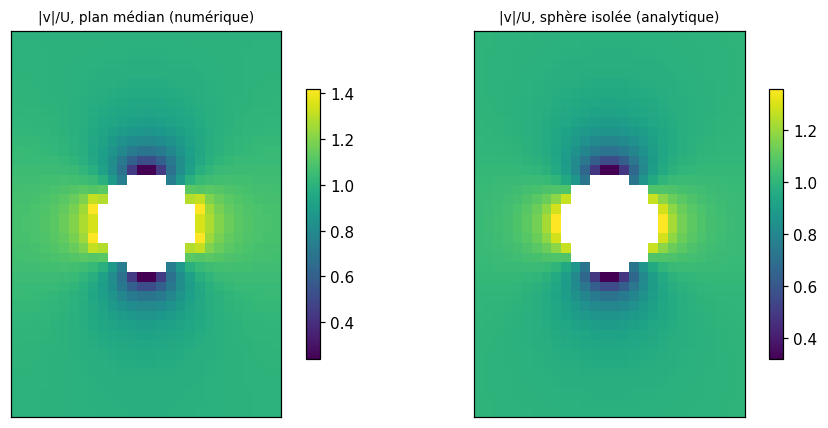

In [13]:
import itertools
n3 = (28, 28, 40); R3 = 5; g3 = Grid(n3, (1.0, 1.0, 1.0)); c3 = [s / 2 for s in n3]
o = (np.arange(4) + 0.5) / 4; acc = np.zeros(n3)
for dx, dy, dz in itertools.product(o, o, o):
    Xg, Yg, Zg = np.meshgrid(np.arange(n3[0]) + dx, np.arange(n3[1]) + dy, np.arange(n3[2]) + dz, indexing="ij")
    acc += ((Xg - c3[0]) ** 2 + (Yg - c3[1]) ** 2 + (Zg - c3[2]) ** 2 <= R3 ** 2)
rho3 = torch.tensor(acc / 64)
pf3 = PotentialFlow(g3, torch.full(n3[:2], 1.0), n_pad=4)
t = time.time(); st3 = pf3.solve(rho3); print(f"résolution 3D, {g3.n_elems} éléments, {g3.n_nodes} nœuds : {time.time()-t:.1f} s ; flux {pf3.fluxes(rho3)}")
sp3 = st3.v.pow(2).sum(-1).sqrt().reshape(n3).numpy()
Xg, Yg, Zg = np.meshgrid(np.arange(n3[0]) + .5, np.arange(n3[1]) + .5, np.arange(n3[2]) + .5, indexing="ij")
r3 = np.sqrt((Xg - c3[0]) ** 2 + (Yg - c3[1]) ** 2 + (Zg - c3[2]) ** 2); mu = np.abs(Zg - c3[2]) / np.maximum(r3, 1e-9); s3 = (R3 / np.maximum(r3, R3)) ** 3
exact3 = np.sqrt((1 - s3) ** 2 * mu**2 + (1 + s3 / 2) ** 2 * (1 - mu**2))
sel = (r3 > 1.5 * R3) & (r3 < 2.5 * R3)
print(f"erreur moyenne de |v|/U sur 1,5R–2,5R : {np.abs(sp3 - exact3)[sel].mean():.4f} ; blocage (section du corps / section de la veine) : {np.pi*R3**2/(n3[0]*n3[1]):.3f}")
print(f"vitesse maximale dans le fluide hors couche d'interface (r > R + 1,5) : {sp3[r3 > R3 + 1.5].max():.3f} (analytique à cette distance : {exact3[(r3 > R3+1.5)&(r3 < R3+2.5)].max():.3f})")
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
j = n3[1] // 2
im = ax[0].imshow(np.where(rho3.numpy()[:, j, :] > 0.5, np.nan, sp3[:, j, :]).T, origin="lower", cmap="viridis"); plt.colorbar(im, ax=ax[0], shrink=0.7); ax[0].set_title("|v|/U, plan médian (numérique)", fontsize=9)
im = ax[1].imshow(np.where(rho3.numpy()[:, j, :] > 0.5, np.nan, exact3[:, j, :]).T, origin="lower", cmap="viridis"); plt.colorbar(im, ax=ax[1], shrink=0.7); ax[1].set_title("|v|/U, sphère isolée (analytique)", fontsize=9)
for a in ax: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

La sphère donne $3\,\%$ d'écart sur l'anneau, avec un blocage de $10\,\%$ en section : même ordre que le cylindre. La vitesse maximale hors couche d'interface ($1{,}31$) est $7\,\%$ au-dessus de la valeur de la sphère isolée à la même distance ($1{,}22$), ce que le blocage explique qualitativement (l'écart n'a pas été isolé, comme il l'a été en 2D). Le code 3D marche sans modification, ce qui valide le choix de l'architecture (contrat C-FLOW-09 : aucun assembleur dédié au fluide). Le coût de la résolution directe 3D (quelques secondes pour $31\,000$ éléments) croît vite avec la taille ; les grilles du projet relèveront du gradient conjugué et du multigrille de la phase 6, comme pour l'élasticité.

## 10. Bilan

| Constat | Où c'est dans le code |
|---|---|
| Laplace = élasticité avec 1 inconnue/nœud : même grille, même opérateur, même solveur, même adjoint | `StructuredFEOperator(ncomp=1)`, C-FLOW-09 |
| Matrice élémentaire symétrique, $\mathbf K\mathbf 1=\mathbf 0$, rang $2^d-1$ ; le stencil Q1 annule les harmoniques de degré $\le2$ | `laplace_ke0`, C-ELEM-06 |
| Sans sortie imposée, le système est singulier et sans solution si le flux total est non nul ; avec la sortie, il est défini positif | §3, C-FLOW-07 |
| Écoulement uniforme exact à la précision machine, flux conservé | C-FLOW-02, 03 |
| Cas lisse à solution exacte : erreur de vitesse en $h^2$ | §6, C-FLOW-08 |
| Cylindre : $C_p=1-4\sin^2\theta$ retrouvé ; l'écart de quelques % vient du **blocage** des parois, pas du maillage | §6, C-FLOW-04 |
| Cylindre diffus : ordre de convergence $\approx0{,}7$–$1{,}4$, irrégulier | §6 |
| $\kappa_{\min}$ fixe l'étanchéité (fuite $\propto\kappa_{\min}$) ; $q$ influe surtout sur la couche d'interface | §7, C-FLOW-06 |
| Un solide collé à l'entrée donne $|\mathbf v|\sim1/\kappa_{\min}$ : tampon obligatoire | §8, C-FLOW-05 |
| Le même code résout la sphère 3D à $3\,\%$ près | §9 |

**Limites à retenir.**
- **Le modèle est irrotationnel et sans viscosité** : il ne sait rien du décollement ni du sillage. Il donne la vitesse **à l'extérieur** de la couche limite, pas la force qui s'exerce sur le corps. C'est l'objet du notebook 15.
- **La veine du projet est bornée** : les parois glissantes accélèrent l'écoulement autour de l'obstacle d'autant plus que le blocage est grand ; le domaine de calcul doit être grand devant le bras, pas seulement le contenir.
- **L'interface diffuse est la principale source d'erreur** autour du corps (la couche d'une cellule), pas le maillage. Cela affectera directement la pression sur le corps (notebook 15).
- **$\kappa_{\min}$ et $q$** sont des choix, validés ici seulement sur des fractions d'aire exactes.
- **Pas de validation contre des mesures** : la solution de référence est analytique, pour le modèle potentiel. Savoir si ce modèle représente le drone relève de la comparaison avec des essais ou de la CFD.

**Pour expérimenter.** (i) Au §6, essayez un obstacle carré : que devient $C_p$ aux coins ? (la solution potentielle y est singulière : vitesse infinie). (ii) Au §4, changez la condition de sortie en la fixant sur une partie seulement de la face du bas : le jet se déporte-t-il ? (iii) Au §7, tracez l'erreur de couche en fonction de $q$ pour $\kappa_{\min}$ différent. (iv) Au §8, augmentez le bloc jusqu'à toute la largeur moins deux cellules : le blocage diverge-t-il ?

*Suite : leçon 15 (forces fluides et paradoxe de d'Alembert). Voir le [plan des leçons](README.md).*